In [1]:
%% MIT 18.03 Lecture 27: Laplace Transform II, Transfer Functions & Partial Fractions
% Description: Demonstrates Laplace IVP resolution using Control System Toolbox:
%              1) Warm-up s-shift verification: L[e^{-t}cos(3t)] = (s+1)/(s^2 + 2s + 10).
%              2) Partial fraction expansion (Cover-up method) via 'residue'.
%              3) Decomposition of non-zero IC problem (x' + 3x = e^{-t}, x(0+)=5)
%                 into Zero-State Response (ZSR) and Zero-Input Response (ZIR).
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, impulse, pzplot, pole).
%
% % MBD Concept Mapping: Defines the Transfer Function W(s) = L[w(t)] = 1/p(s).
% %                      Decomposes rational s-domain expressions into modal residues,
% %                      and separates forced response from initial state decay.


clear; clc; close all;


%% =========================================================================
%% Part 1: Warm-up s-Shift & Partial Fractions (Cover-up Method)
%% =========================================================================
s = tf('s');


% Warm-up: f(t) = exp(-t)*cos(3t) <---> F(s) = (s + 1) / (s^2 + 2s + 10)
F_warmup = (s + 1) / (s^2 + 2*s + 10);


% Section [5] Partial Fractions: X_zsr(s) = 1 / ((s + 1)*(s + 3)) = 1 / (s^2 + 4s + 3)
num_zsr = 1;
den_zsr = conv([1, 1], [1, 3]); % (s + 1)(s + 3) = s^2 + 4s + 3
[residues, poles, direct_term] = residue(num_zsr, den_zsr);


fprintf('=== MIT 18.03 Lecture 27 Cover-Up & Residue Diagnostics ===\n');

=== MIT 18.03 Lecture 27 Cover-Up & Residue Diagnostics ===

In [2]:
fprintf('Rational Function X(s) = 1 / ((s + 1)(s + 3)):\n');

Rational Function X(s) = 1 / ((s + 1)(s + 3)):

In [3]:
for idx = 1:length(poles)
    fprintf('  Pole p_%d = %+.2f  -->  Cover-up Residue R_%d = %+.4f\n', ...
        idx, poles(idx), idx, residues(idx));
end

  Pole p_1 = -3.00  -->  Cover-up Residue R_1 = -0.5000
  Pole p_2 = -1.00  -->  Cover-up Residue R_2 = +0.5000

In [4]:
fprintf('Analytical Check: a = +1/2 at s = -1, b = -1/2 at s = -3.\n');

Analytical Check: a = +1/2 at s = -1, b = -1/2 at s = -3.

In [5]:
fprintf('===========================================================\n\n');


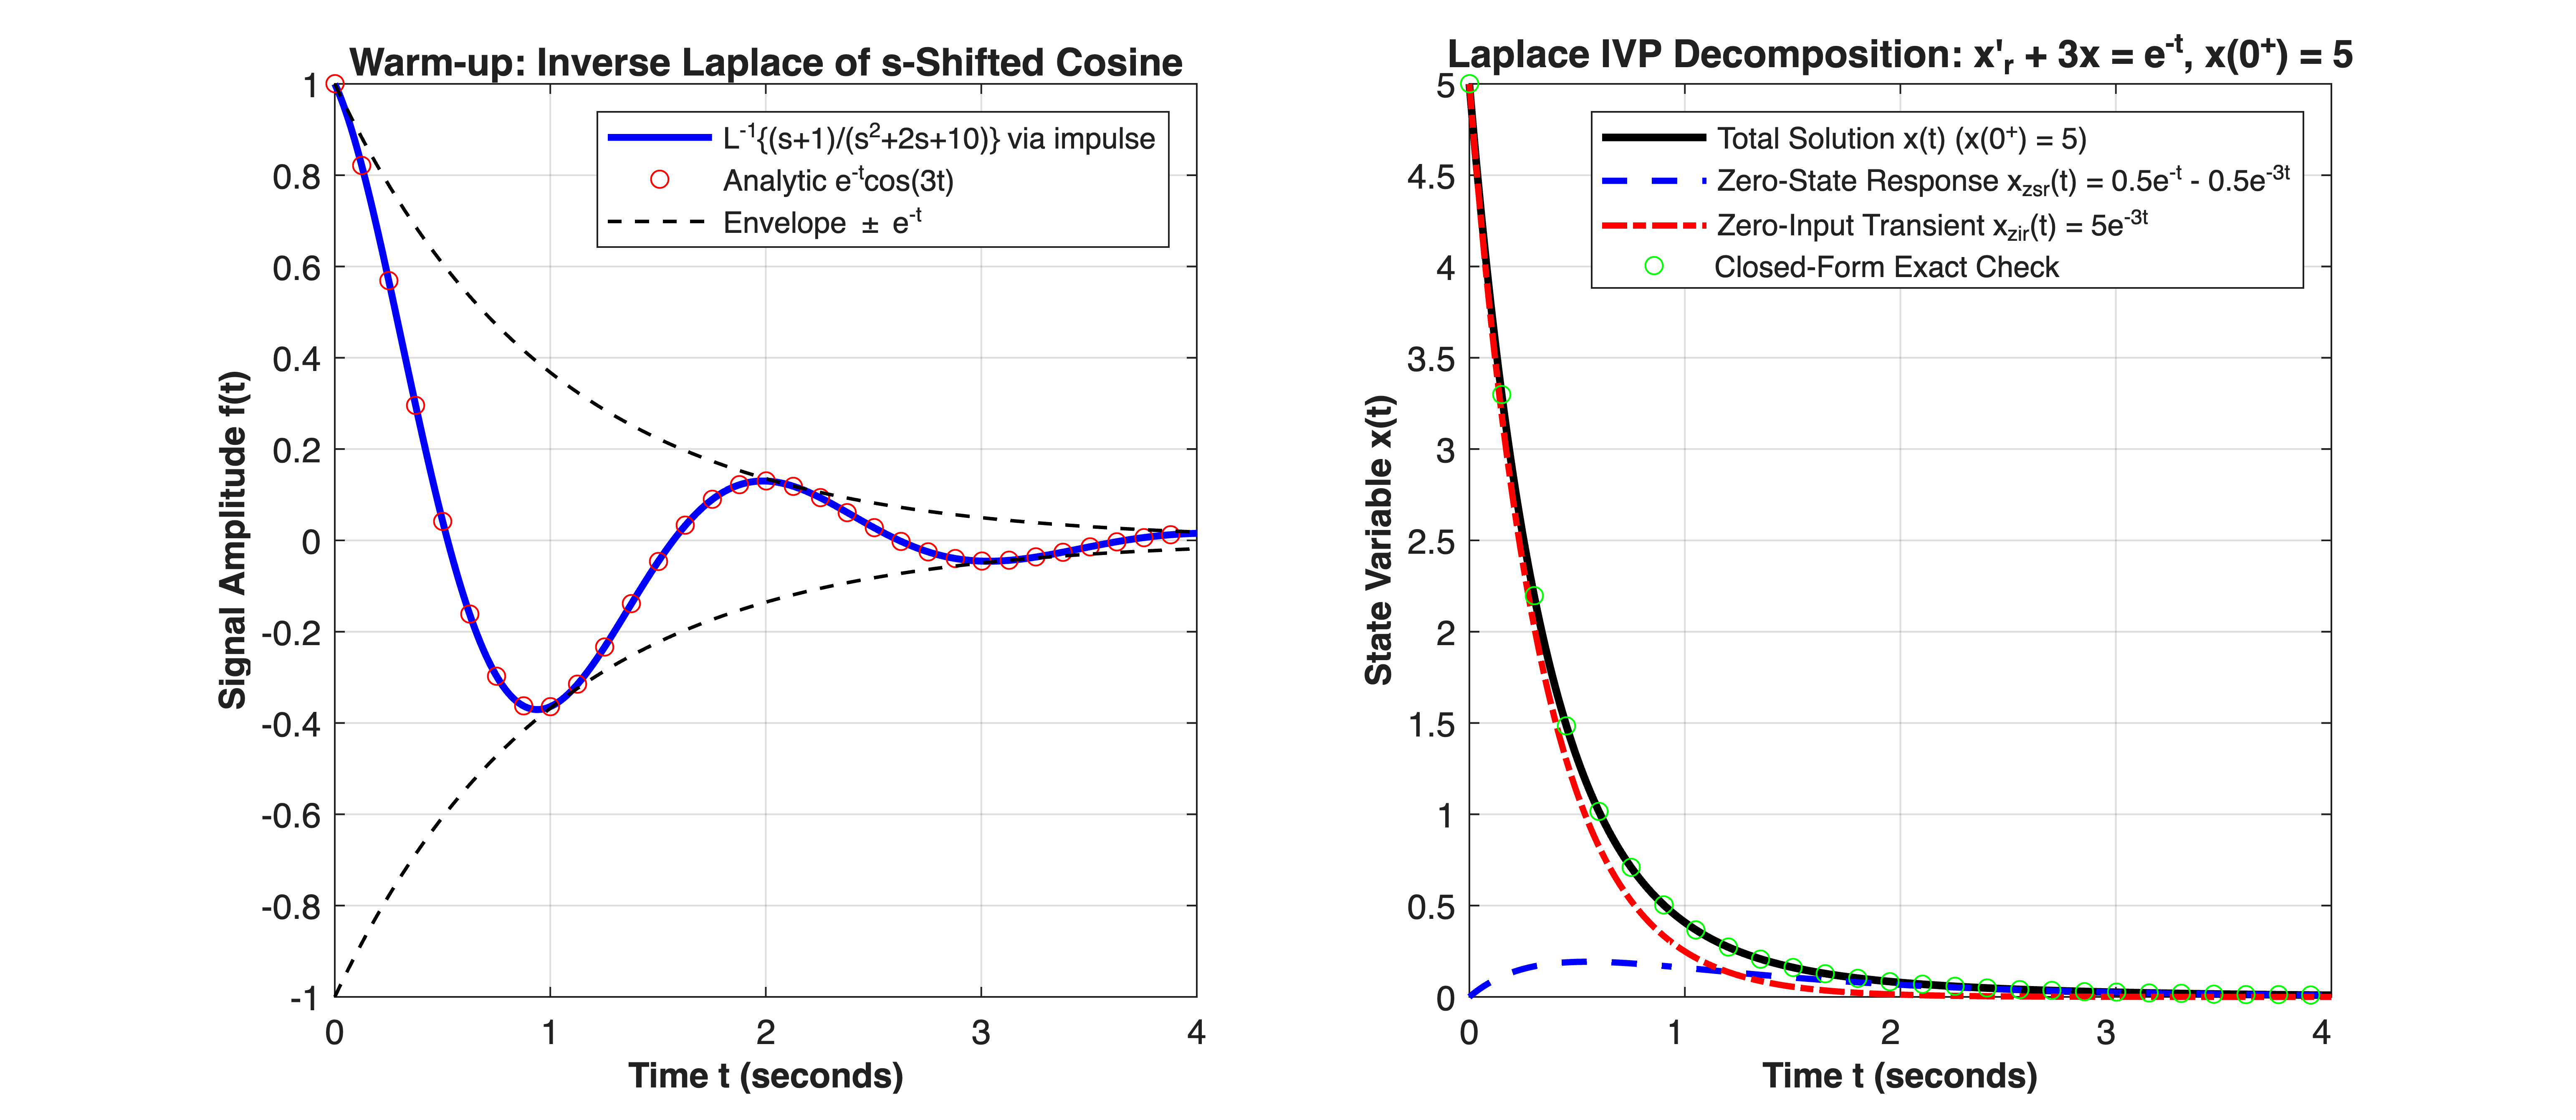

In [6]:


%% =========================================================================
%% Part 2: Non-Zero Initial Condition IVP (ZSR + ZIR Decomposition)
%% =========================================================================
% Equation: x'_r + 3x = e^{-t}, with x(0+) = 5
% In s-domain: (s*X(s) - 5) + 3*X(s) = 1/(s + 1)
% X(s) = 1 / ((s + 1)*(s + 3)) + 5 / (s + 3) = X_zsr(s) + X_zir(s)
x0_val = 5.0;


X_zsr_tf   = 1 / ((s + 1) * (s + 3));
X_zir_tf   = x0_val / (s + 3);
X_total_tf = X_zsr_tf + X_zir_tf;


t_eval = linspace(0, 4.0, 800);


% Recover time-domain signals via Control System Toolbox 'impulse' (L^-1 operator)
[x_warmup, ~] = impulse(F_warmup, t_eval);
[x_zsr, ~]    = impulse(X_zsr_tf, t_eval);
[x_zir, ~]    = impulse(X_zir_tf, t_eval);
[x_total, ~]  = impulse(X_total_tf, t_eval);


% Exact analytical solution: x(t) = 0.5*e^{-t} - 0.5*e^{-3t} + 5*e^{-3t} = 0.5*e^{-t} + 4.5*e^{-3t}
x_exact = 0.5 * exp(-t_eval) + 4.5 * exp(-3 * t_eval);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 500]);


% Subplot 1: Warm-up Damped Cosine Reconstruction
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_eval, x_warmup, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', 'L^{-1}\{(s+1)/(s^2+2s+10)\} via impulse');
plot(t_eval(1:25:end), exp(-t_eval(1:25:end)).*cos(3*t_eval(1:25:end)), 'ro', ...
    'MarkerSize', 5, 'DisplayName', 'Analytic e^{-t}cos(3t)');
plot(t_eval, exp(-t_eval), 'k--', 'LineWidth', 1.0, 'DisplayName', 'Envelope \pm e^{-t}');
plot(t_eval, -exp(-t_eval), 'k--', 'LineWidth', 1.0, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Signal Amplitude f(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Warm-up: Inverse Laplace of s-Shifted Cosine', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 4.0]);


% Subplot 2: IVP Decomposition (Zero-State vs. Zero-Input Response)
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_eval, x_total, 'k-', 'LineWidth', 2.2, ...
    'DisplayName', 'Total Solution x(t) (x(0^+) = 5)');
plot(t_eval, x_zsr, 'b--', 'LineWidth', 1.8, ...
    'DisplayName', 'Zero-State Response x_{zsr}(t) = 0.5e^{-t} - 0.5e^{-3t}');
plot(t_eval, x_zir, 'r-.', 'LineWidth', 1.8, ...
    'DisplayName', 'Zero-Input Transient x_{zir}(t) = 5e^{-3t}');
plot(t_eval(1:30:end), x_exact(1:30:end), 'go', 'MarkerSize', 5, ...
    'DisplayName', 'Closed-Form Exact Check');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Variable x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title("Laplace IVP Decomposition: x'_r + 3x = e^{-t}, x(0^+) = 5", ...
    'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 4.0]);